Write a program to enhance the contrast of the input grayscale image
using histogram equalization. Display the original image and equalized
image.
● Write a program to perform histogram matching of the input image with
that of reference image using histogram equalization

Upload the input image:


Saving Spider Lily.jpeg to Spider Lily.jpeg
Image loaded successfully.
Image size: (1307, 736)


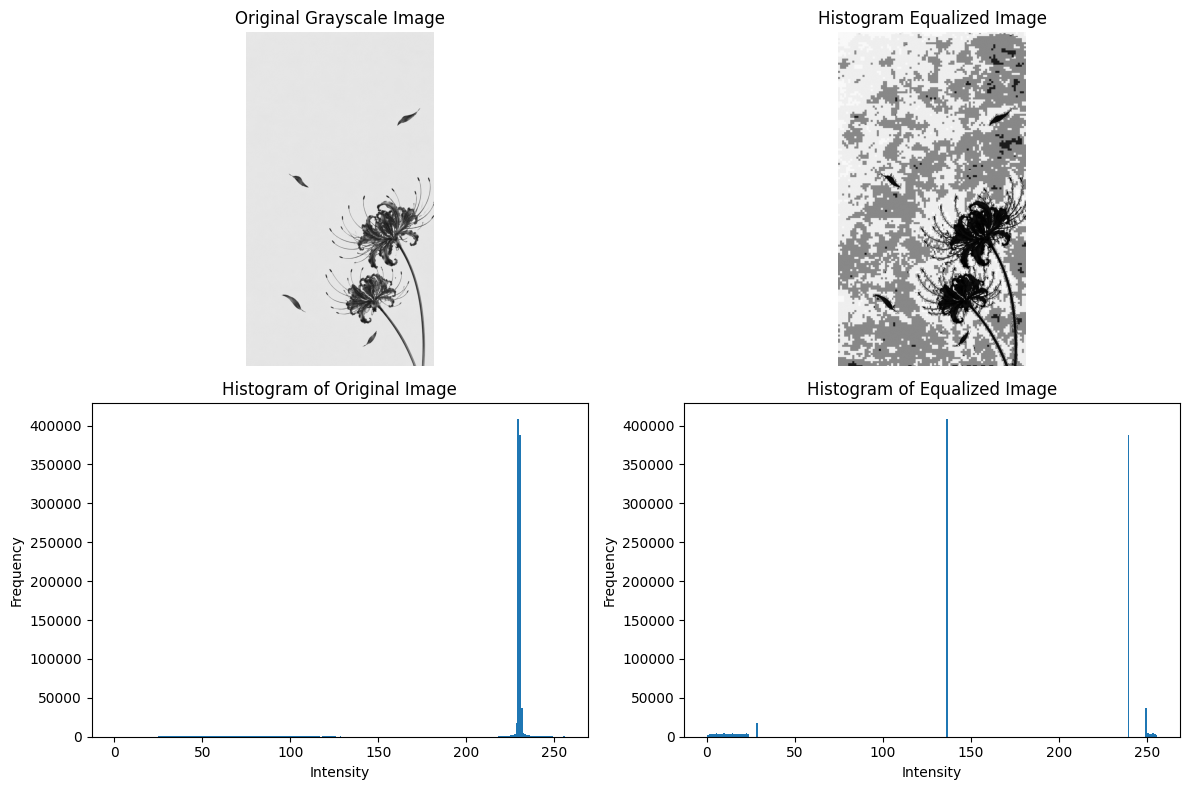

Equalized image saved as: equalized_image.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================
# HISTOGRAM EQUALIZATION
# Contrast Enhancement of Grayscale Image
# ============================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# --------------------------------------------
# 1. Upload Image
# --------------------------------------------

print("Upload the input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read image in grayscale
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully.")
print("Image size:", img.shape)


# --------------------------------------------
# 2. Histogram Equalization
# --------------------------------------------

equalized_img = cv2.equalizeHist(img)


# --------------------------------------------
# 3. Display Original and Equalized Images
# --------------------------------------------

plt.figure(figsize=(12, 8))

# Original image
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

# Equalized image
plt.subplot(2, 2, 2)
plt.imshow(equalized_img, cmap='gray')
plt.title("Histogram Equalized Image")
plt.axis("off")

# Original histogram
plt.subplot(2, 2, 3)
plt.hist(img.ravel(), bins=256, range=[0, 256])
plt.title("Histogram of Original Image")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

# Equalized histogram
plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), bins=256, range=[0, 256])
plt.title("Histogram of Equalized Image")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# --------------------------------------------
# 4. Save Result
# --------------------------------------------

cv2.imwrite("equalized_image.jpg", equalized_img)

print("Equalized image saved as: equalized_image.jpg")

files.download("equalized_image.jpg")

Upload the INPUT image:


Saving Spider Lily.jpeg to Spider Lily (1).jpeg

Upload the REFERENCE image:


Saving Spider Lily.jpeg to Spider Lily (2).jpeg


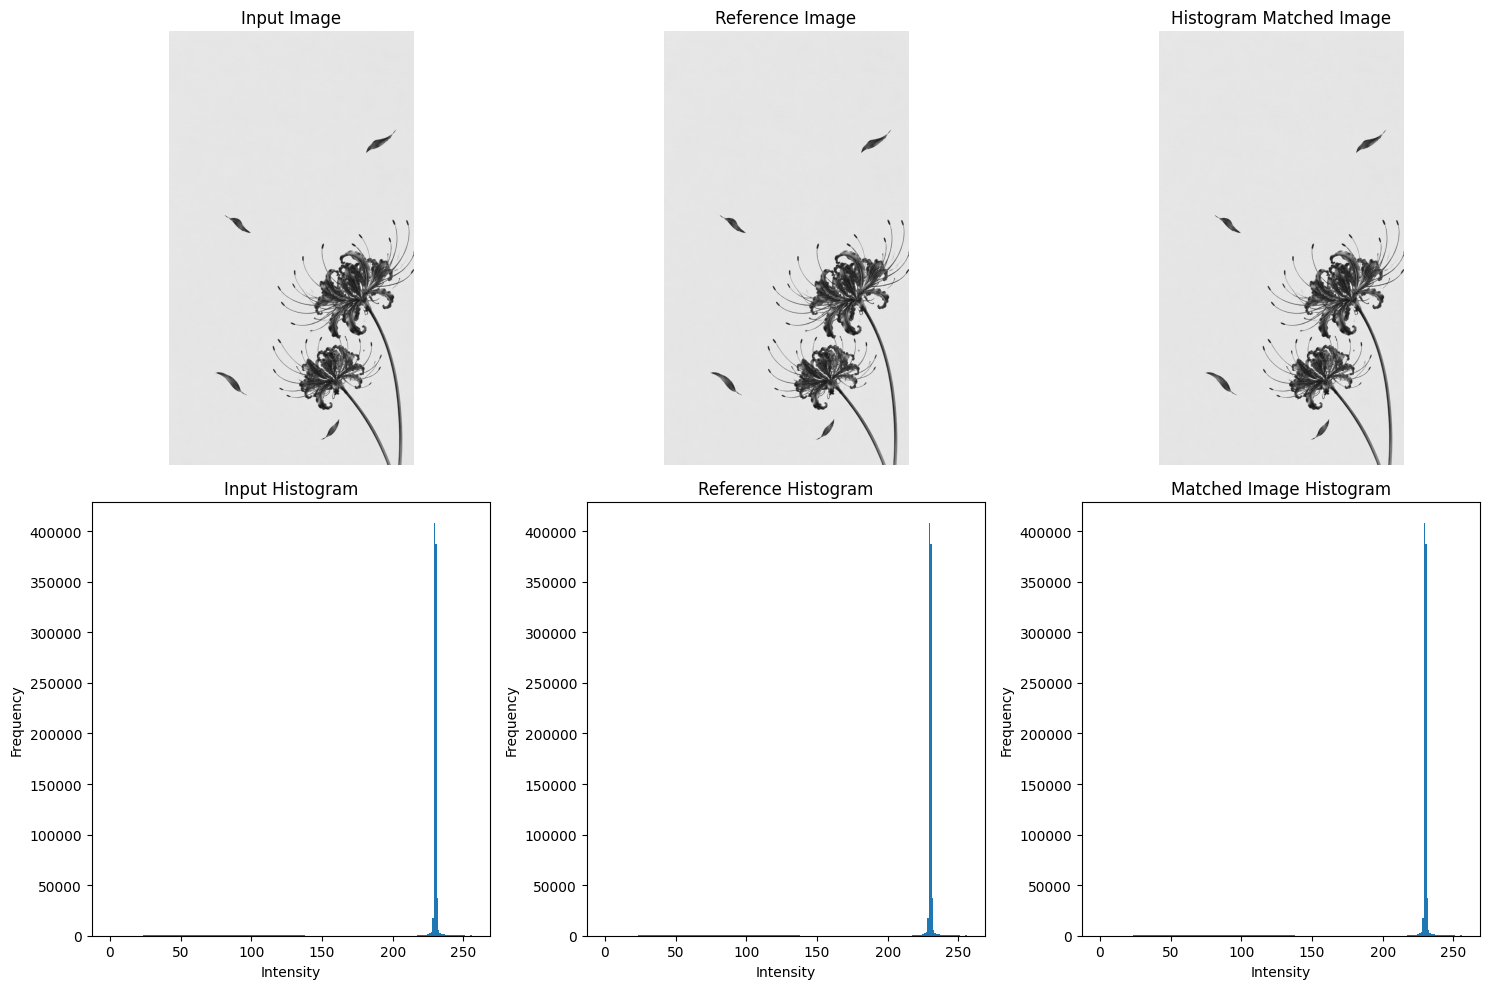


Histogram matched image saved as:
histogram_matched_image.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================
# HISTOGRAM MATCHING
# Input Image -> Reference Image
# ============================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# --------------------------------------------
# 1. Upload Input Image
# --------------------------------------------

print("Upload the INPUT image:")
uploaded_input = files.upload()

input_filename = next(iter(uploaded_input))

input_img = cv2.imread(
    input_filename,
    cv2.IMREAD_GRAYSCALE
)

if input_img is None:
    raise ValueError("Input image could not be loaded.")


# --------------------------------------------
# 2. Upload Reference Image
# --------------------------------------------

print("\nUpload the REFERENCE image:")
uploaded_reference = files.upload()

reference_filename = next(iter(uploaded_reference))

reference_img = cv2.imread(
    reference_filename,
    cv2.IMREAD_GRAYSCALE
)

if reference_img is None:
    raise ValueError("Reference image could not be loaded.")


# --------------------------------------------
# 3. Calculate Histograms
# --------------------------------------------

input_hist = cv2.calcHist(
    [input_img],
    [0],
    None,
    [256],
    [0, 256]
).ravel()

reference_hist = cv2.calcHist(
    [reference_img],
    [0],
    None,
    [256],
    [0, 256]
).ravel()


# --------------------------------------------
# 4. Calculate CDFs
# --------------------------------------------

input_cdf = input_hist.cumsum()
reference_cdf = reference_hist.cumsum()

# Normalize CDFs
input_cdf = input_cdf / input_cdf[-1]
reference_cdf = reference_cdf / reference_cdf[-1]


# --------------------------------------------
# 5. Create Mapping
# --------------------------------------------

mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):

    # Find intensity in reference image
    # having closest CDF value
    j = np.argmin(
        np.abs(reference_cdf - input_cdf[i])
    )

    mapping[i] = j


# --------------------------------------------
# 6. Apply Mapping
# --------------------------------------------

matched_img = mapping[input_img]


# --------------------------------------------
# 7. Display Images
# --------------------------------------------

plt.figure(figsize=(15, 10))

# Input image
plt.subplot(2, 3, 1)
plt.imshow(input_img, cmap='gray')
plt.title("Input Image")
plt.axis("off")

# Reference image
plt.subplot(2, 3, 2)
plt.imshow(reference_img, cmap='gray')
plt.title("Reference Image")
plt.axis("off")

# Matched image
plt.subplot(2, 3, 3)
plt.imshow(matched_img, cmap='gray')
plt.title("Histogram Matched Image")
plt.axis("off")


# --------------------------------------------
# 8. Display Histograms
# --------------------------------------------

plt.subplot(2, 3, 4)
plt.hist(input_img.ravel(), bins=256, range=[0, 256])
plt.title("Input Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.subplot(2, 3, 5)
plt.hist(reference_img.ravel(), bins=256, range=[0, 256])
plt.title("Reference Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.subplot(2, 3, 6)
plt.hist(matched_img.ravel(), bins=256, range=[0, 256])
plt.title("Matched Image Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# --------------------------------------------
# 9. Save Output
# --------------------------------------------

cv2.imwrite("histogram_matched_image.jpg", matched_img)

print("\nHistogram matched image saved as:")
print("histogram_matched_image.jpg")

files.download("histogram_matched_image.jpg")